In [1]:
import pandas as pd
from hmm_logic_methods import load_model
import pomegranate
from pomegranate.distributions import DiscreteDistributionCycle
import os
EXPERIMENT_NAME_TO_READ = 'multiple_single_allele_models'
TARGET_PATH_TO_RESULTS = f"experiment_results/{EXPERIMENT_NAME_TO_READ}/" #!CHANGE for bwv!
check_peptides = True
initial_params = None

C:\Users\denkl\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm

KeyboardInterrupt



In [ ]:
models_to_read = os.listdir(TARGET_PATH_TO_RESULTS)

In [ ]:
per_name_models = {model_name: load_model(TARGET_PATH_TO_RESULTS, model_name) for model_name in models_to_read}
model_names = list(per_name_models.keys())

In [ ]:
len(model_names)

In [ ]:
from collections import defaultdict
model_alleles = list()
random_peptides_alleles = list()
model_allele_to_matrix = dict()
random_peptides_allele_to_matrix = dict()
random_models_counters = defaultdict(int)
model_models_countsers = defaultdict(int)

for model_name in model_names:
    current_model = per_name_models[model_name]
    current_alelle = f"{current_model.name.split('-')[-2]}"
    model_distributions = [state.distribution.parameters[0] for state in current_model.states if (state.distribution is not None) and (type(state.distribution) is not DiscreteDistributionCycle)]
    current_matrix = pd.DataFrame(model_distributions)
    current_matrix.index.name = 'pos'
    if "decoy_allele" in model_name:
        random_models_counters[current_alelle] += 1
        if current_alelle not in random_peptides_allele_to_matrix:
            random_peptides_alleles.append(current_alelle)
            random_peptides_allele_to_matrix[current_alelle] = current_matrix
        else:
            random_peptides_allele_to_matrix[current_alelle] = random_peptides_allele_to_matrix[current_alelle] + current_matrix
    else:
        model_models_countsers[current_alelle] += 1
        if current_alelle not in model_allele_to_matrix:
            model_alleles.append(current_alelle)
            model_allele_to_matrix[current_alelle] = current_matrix
        else:
            model_allele_to_matrix[current_alelle] = model_allele_to_matrix[current_alelle] + current_matrix

for allele_name in random_models_counters:
    random_peptides_allele_to_matrix[allele_name] =random_peptides_allele_to_matrix[allele_name].div(random_peptides_allele_to_matrix[allele_name].sum(axis=1), axis=0)
for allele_name in model_models_countsers:
    model_allele_to_matrix[allele_name] = model_allele_to_matrix[allele_name].div(model_allele_to_matrix[allele_name].sum(axis=1), axis=0)

# Make additional data
## MixMHCpred
### Read the data

In [57]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
MIXMHCPRED_DATA_EXTERNAL_PATH = f'{DATA_PATH_BASE}/Binding data/MixMHC2pred/train_data/external_studies.csv'
MIXMHCPRED_DATA_INHOUSE_PATH = f'{DATA_PATH_BASE}/Binding data/MixMHC2pred/train_data/current_study.csv'

df_external = pd.read_csv(MIXMHCPRED_DATA_EXTERNAL_PATH,sep=";")
df_external.columns = list(map(str.lower, df_external.columns))
df_inhouse = pd.read_csv(MIXMHCPRED_DATA_INHOUSE_PATH,sep=";")
df_inhouse.columns = list(map(str.lower, df_inhouse.columns))

## Keep only with cores known and length of core == 9

In [58]:
df_external = df_external[df_external.core.str.len() > 0]
df_inhouse = df_inhouse[df_inhouse.core.str.len() > 0]
df_external['core_len'] = df_external.core.str.len()
df_inhouse['core_len'] = df_inhouse.core.str.len()
df_external = df_external[df_external.core_len == 9]
df_external = df_external[~df_external.allele.str.contains(" or ")]
df_external = df_external[~df_external.allele.str.contains("Contamination")]

df_inhouse = df_inhouse[df_inhouse.core_len == 9]
df_inhouse = df_inhouse[~df_inhouse.allele.str.contains(" or ")]
df_inhouse = df_inhouse[~df_inhouse.allele.str.contains("Contamination")]

### Check. make logo

In [59]:
import seaborn as sns
import logomaker
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

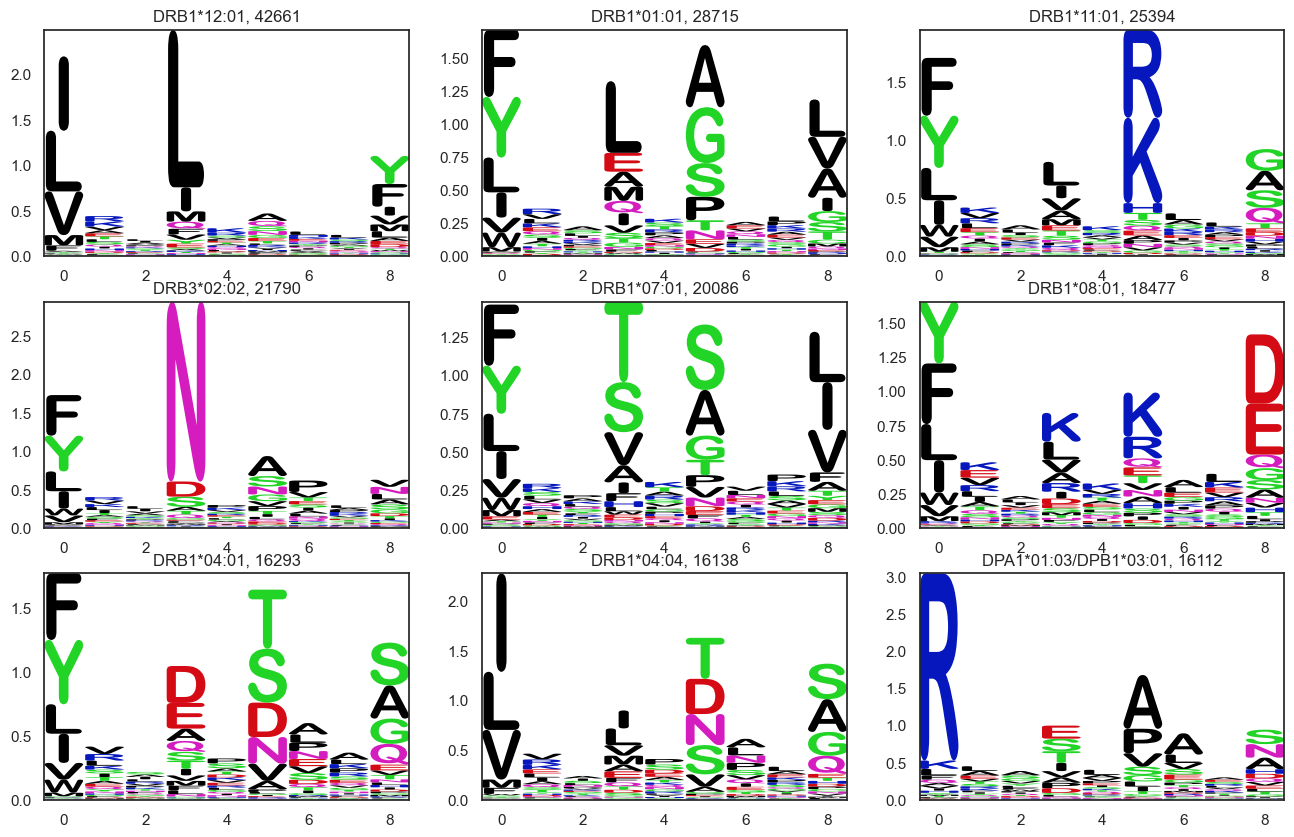

In [60]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3,3, figsize=(16,10))

make_logo_for_data(df_external[df_external.allele == 'DRB1*12:01'].core.values, "DRB1*12:01", ax=axes[0,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*01:01'].core.values, "DRB1*01:01",ax=axes[0,1])
make_logo_for_data(df_external[df_external.allele == 'DRB1*11:01'].core.values, "DRB1*11:01",ax=axes[0,2])
make_logo_for_data(df_external[df_external.allele == 'DRB3*02:02'].core.values, "DRB3*02:02", ax=axes[1,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*07:01'].core.values, "DRB1*07:01", ax=axes[1,1])
make_logo_for_data(df_external[df_external.allele == 'DRB1*08:01'].core.values, "DRB1*08:01", ax=axes[1,2])
make_logo_for_data(df_external[df_external.allele == 'DRB1*04:01'].core.values, "DRB1*04:01", ax=axes[2,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*04:04'].core.values, "DRB1*04:04", ax=axes[2,1])
make_logo_for_data(df_external[df_external.allele == 'DPA1*01:03/DPB1*03:01'].core.values, "DPA1*01:03/DPB1*03:01", ax=axes[2,2])


## Decoy data with fake cores
### Shred big dataframe to smaller ones

In [61]:
class_to_use = 'II'
organism = 'Human'
DECOY_DATA_PATH = f"{DATA_PATH_BASE}\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
decoy_df =  pd.read_csv(DECOY_DATA_PATH)

decoy_df =decoy_df.iloc[:int(len(decoy_df)/12000)*12000]
decoy_df['core'] = decoy_df.peptide.str.slice(0,9)
decoy_df['core_len'] = decoy_df.core.str.len()
decoy_df['allele'] = [ f'decoy_allele_{j}'  for j in range(int(len(decoy_df)/12000)) for i in range(12000)]
len(decoy_df)

3396000

In [62]:
len(decoy_df.allele.unique())

283

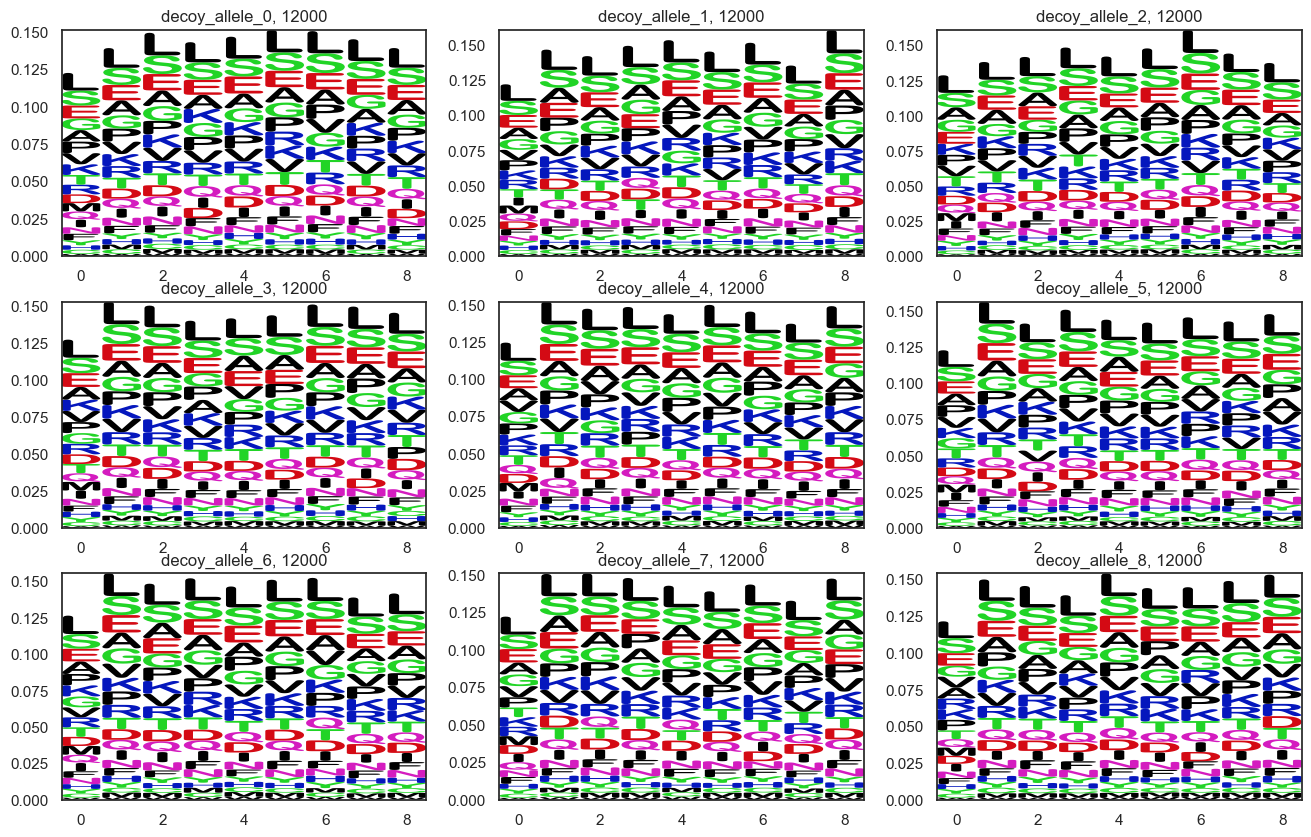

In [63]:
fig, axes = plt.subplots(3,3, figsize=(16,10))

make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_0'].core.values, "decoy_allele_0", ax=axes[0,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_1'].core.values, "decoy_allele_1",ax=axes[0,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_2'].core.values, "decoy_allele_2",ax=axes[0,2])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_3'].core.values, "decoy_allele_3", ax=axes[1,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_4'].core.values, "decoy_allele_4", ax=axes[1,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_5'].core.values, "decoy_allele_5", ax=axes[1,2])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_6'].core.values, "decoy_allele_6", ax=axes[2,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_7'].core.values, "decoy_allele_7", ax=axes[2,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_8'].core.values, "decoy_allele_8", ax=axes[2,2])

### Based on this data get natural frequencies for amino acids

In [64]:
natural_distribution_of_aas = logomaker.alignment_to_matrix(decoy_df.core.values, to_type='probability')
natural_distribution_of_aas

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.066470,0.021098,0.047650,0.070905,0.035178,0.062337,0.025244,0.043243,0.057427,0.096161,0.048262,0.035963,0.059660,0.046936,0.054387,0.080709,0.052072,0.058573,0.011643,0.026081
1,0.072670,0.021394,0.049358,0.073551,0.035895,0.064253,0.025589,0.043923,0.058732,0.097830,0.020121,0.036813,0.061120,0.048146,0.055557,0.083785,0.052932,0.059797,0.012136,0.026400
2,0.069118,0.021588,0.048783,0.073203,0.036093,0.064614,0.025921,0.044076,0.058688,0.098571,0.020067,0.037057,0.061907,0.048493,0.056557,0.083373,0.053571,0.059865,0.012002,0.026451
3,0.068862,0.021655,0.048610,0.072794,0.036279,0.064313,0.025824,0.044254,0.059194,0.098881,0.019957,0.036961,0.062012,0.048469,0.056567,0.083277,0.053352,0.060036,0.012122,0.026580
4,0.068845,0.021720,0.048782,0.072919,0.036159,0.064450,0.025756,0.044398,0.059172,0.098939,0.020192,0.036688,0.061690,0.048499,0.056249,0.083137,0.053281,0.060281,0.012219,0.026624
5,0.068659,0.021726,0.048920,0.072867,0.036002,0.064652,0.025919,0.044235,0.059002,0.099314,0.020052,0.036728,0.061724,0.048412,0.056468,0.083329,0.053338,0.059835,0.012190,0.026628
6,0.068586,0.021613,0.048698,0.073018,0.036042,0.064504,0.026101,0.044385,0.058796,0.099350,0.020060,0.036957,0.061657,0.048323,0.056445,0.082763,0.053580,0.060264,0.012032,0.026825
7,0.068583,0.021718,0.048702,0.072810,0.036168,0.064363,0.026049,0.044105,0.058974,0.099163,0.020091,0.036816,0.061886,0.048507,0.056477,0.083116,0.053370,0.060089,0.012238,0.026777
8,0.068831,0.021862,0.048880,0.072515,0.036077,0.064294,0.026190,0.044410,0.058693,0.099245,0.020075,0.036795,0.061539,0.048605,0.056547,0.082922,0.053510,0.060297,0.012115,0.026599


## Simulated data (generate here)
### Generate 1,2,3,4,5,6 anchor cores

In [65]:
import numpy as np
from tqdm import tqdm
from numpy.random import default_rng
# generate a lot of data

rng = default_rng()
set1 = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I','K', 'L']
set2 = ['M', 'N', 'P', 'Q','R', 'S', 'T', 'V', 'W', 'Y']

total_set = set1 + set2

motifs_sequences = list()
number_of_anchors_list = list()
set_group = list()
simulated_alleles = list()
len_of_each_motif = 5000

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(set1) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(set1, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']),p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i}")

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(set2) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(set2, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']), p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i+1000}")

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(total_set) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(total_set, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']),p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i+2000}")


simulated_allele_to_matrix = dict()
for i in tqdm(range(len(motifs_sequences))):
    sequences = motifs_sequences[i]
    cur_matrix = logomaker.alignment_to_matrix(sequences, to_type='probability')
    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    simulated_allele_to_matrix[simulated_alleles[i]] = cur_matrix[natural_distribution_of_aas.columns]

100%|██████████| 3000/3000 [01:58<00:00, 25.36it/s]


### save some annotation info for simulations

In [66]:
simulated_annotation = pd.DataFrame({"allele": simulated_alleles, "number_of_anchors":number_of_anchors_list, "index_in_list": np.arange(len(simulated_alleles))})

In [67]:
for number_of_anchors in range(1,10):
    print("Number of anchors =", number_of_anchors, ":", len(simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors]))

Number of anchors = 1 : 316
Number of anchors = 2 : 333
Number of anchors = 3 : 354
Number of anchors = 4 : 345
Number of anchors = 5 : 301
Number of anchors = 6 : 315
Number of anchors = 7 : 358
Number of anchors = 8 : 333
Number of anchors = 9 : 345


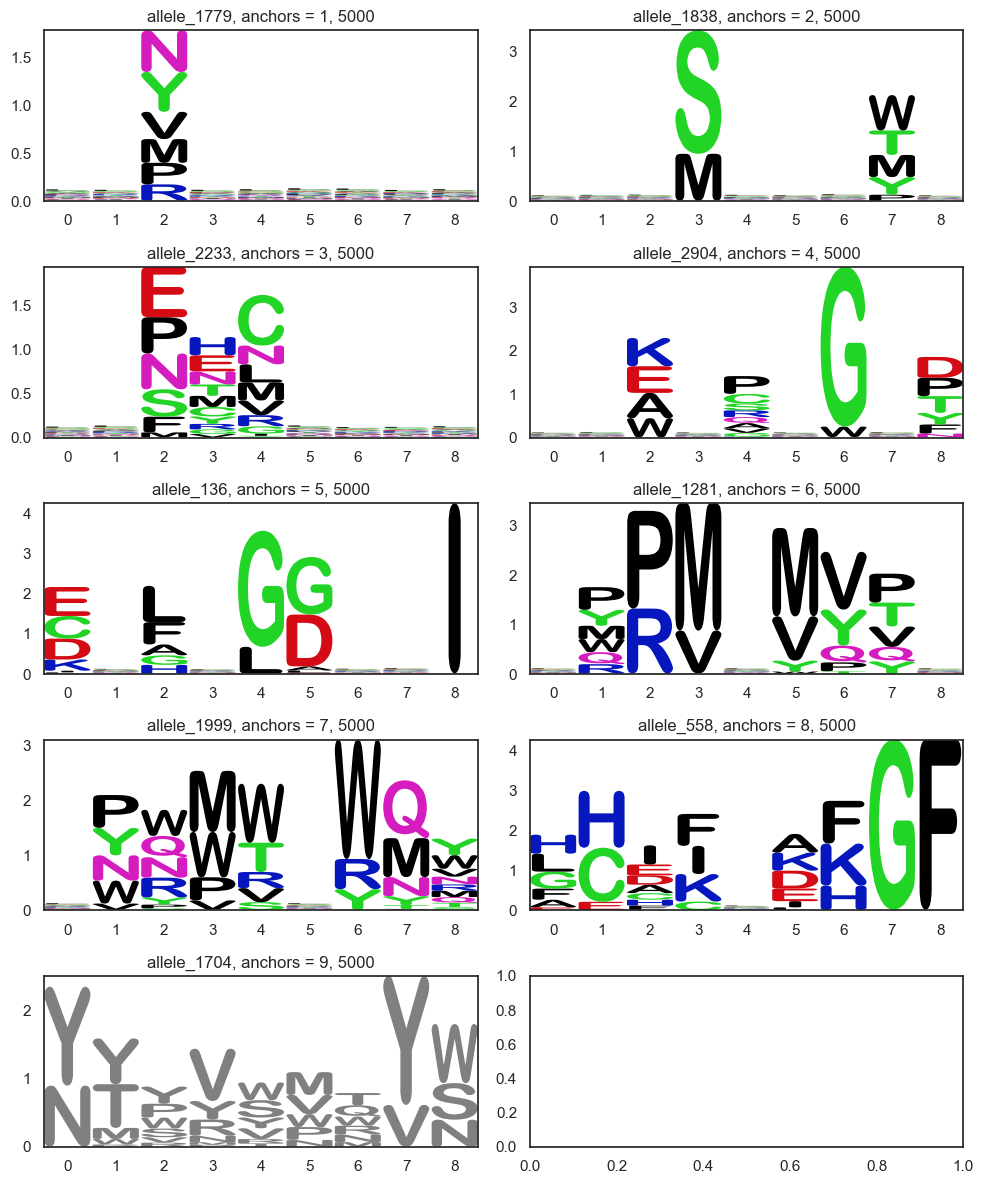

In [68]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(10, 12))
for number_of_anchors, ax_index in zip(range(1,10), np.ndindex(axes.shape)):
    index_of_data = simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors]['index_in_list'].sample().iloc[0]
    make_logo_for_data(motifs_sequences[index_of_data], f"{simulated_alleles[index_of_data]}, anchors = {number_of_anchors}", ax=axes[ax_index])
plt.tight_layout()

## Transform data with cores to distribution matrices  (similarly as we did for simulated data)

In [69]:
alleles_external = df_external.allele.unique()
allele_to_matrix = dict()
from tqdm import tqdm
for allele_name in tqdm(alleles_external):
    cur_matrix = logomaker.alignment_to_matrix(df_external[df_external.allele == allele_name].core.values, to_type='probability')

    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    allele_to_matrix[allele_name] = cur_matrix[natural_distribution_of_aas.columns]


alleles_decoy = decoy_df.allele.unique()
decoy_allele_to_matrix = dict()
for allele_name in tqdm(alleles_decoy):
    cur_matrix = logomaker.alignment_to_matrix(decoy_df[decoy_df.allele == allele_name].core.values, to_type='probability')

    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    decoy_allele_to_matrix[allele_name] = cur_matrix[natural_distribution_of_aas.columns]

100%|██████████| 283/283 [01:14<00:00,  3.82it/s]


# Analyzing these datasets

## Get information vectors for each of the dataset

In [70]:
%%time
external_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in allele_to_matrix.items()}

decoy_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in decoy_allele_to_matrix.items()}

simulated_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in simulated_allele_to_matrix.items()}
model_trained_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in model_allele_to_matrix.items()}

random_peptides_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in random_peptides_allele_to_matrix.items()}

CPU times: total: 18.8 s
Wall time: 18.8 s


In [71]:
info_matrix = logomaker.transform_matrix(random_peptides_allele_to_matrix[random_peptides_alleles[2]], from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy())
info_matrix_real_trained = logomaker.transform_matrix(model_allele_to_matrix['HLA_DRB1_01_01'], from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy())

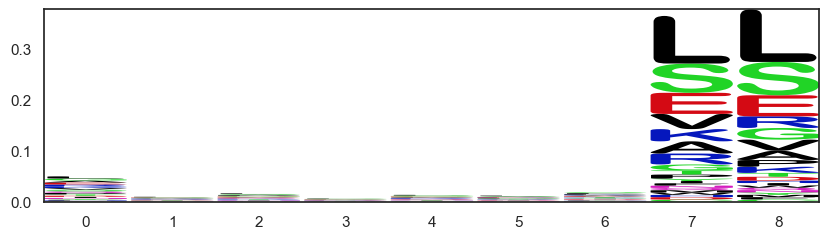

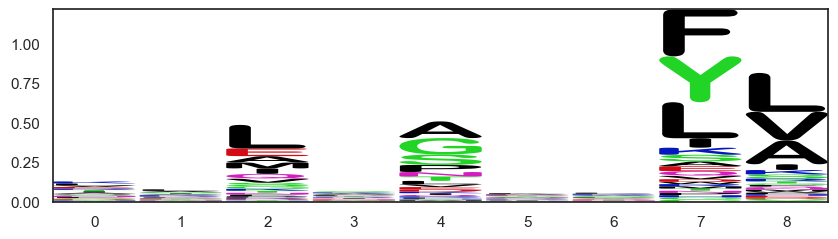

In [72]:
logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
logomaker.Logo(info_matrix_real_trained, font_name='Arial Rounded MT Bold', flip_below=True)

## Get mean vector value for each allele

In [73]:
external_mean_informations = [sum(item)/len(item) for item in external_allele_to_info_vector.values()]
decoy_mean_informations = [sum(item)/len(item) for item in decoy_allele_to_info_vector.values()]
simulated_mean_informations = [sum(item)/len(item) for item in simulated_allele_to_info_vector.values()]
model_trained_mean_informations = [sum(item)/len(item) for item in model_trained_allele_to_info_vector.values()]
random_peptides_mean_informations = [sum(item)/len(item) for item in random_peptides_allele_to_info_vector.values()]


## Plot historgrams of distributions for this value

In [74]:
df_external_info = pd.DataFrame({"allele":external_allele_to_info_vector.keys(), "mean_information":external_mean_informations, 'allele_type':'real_data'})

df_decoy_info = pd.DataFrame({"allele":decoy_allele_to_info_vector.keys(), "mean_information":decoy_mean_informations,'allele_type':'decoy'})

df_model_trained_info = pd.DataFrame({"allele":model_trained_allele_to_info_vector.keys(), "mean_information":model_trained_mean_informations,'allele_type':'model_trained'})
df_random_pep_trained_info = pd.DataFrame({"allele":random_peptides_allele_to_info_vector.keys(), "mean_information":random_peptides_mean_informations,'allele_type':'random_peptides'})

simulated_dfs = list()

for number_of_anchors in range(1,10):
    current_alleles_indexes = list(simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors].index_in_list)
    current_allele_names = np.array(simulated_alleles)[current_alleles_indexes]
    current_information = np.array(simulated_mean_informations)[current_alleles_indexes]
    current_allele_type = f"simulated_anchors={number_of_anchors}"
    current_df_info = pd.DataFrame({"allele":current_allele_names, "mean_information":current_information,'allele_type':current_allele_type})
    simulated_dfs.append(current_df_info)



In [75]:
total_df=pd.concat([df_external_info,df_decoy_info, df_model_trained_info,df_random_pep_trained_info]   + simulated_dfs)
total_df = total_df[total_df.allele != 'Incomplete typing']

### min values for group

In [76]:
total_df.groupby('allele_type').min('mean_information')

,mean_information
allele_type,
decoy,0.000856
model_trained,0.284925
random_peptides,0.074520
real_data,0.444539
simulated_anchors=1,0.121362
simulated_anchors=2,0.246630
simulated_anchors=3,0.360310
simulated_anchors=4,0.542293
simulated_anchors=5,0.706513


## max values for group

In [77]:
total_df.groupby('allele_type').max('mean_information')

,mean_information
allele_type,
decoy,0.001552
model_trained,0.587176
random_peptides,0.115185
real_data,1.267348
simulated_anchors=1,0.719856
simulated_anchors=2,1.106104
simulated_anchors=3,1.640012
simulated_anchors=4,1.861124
simulated_anchors=5,2.456515


### Plot distributions
#### For simulated data

Text(0.5, 1.0, 'Information content per position for cores')

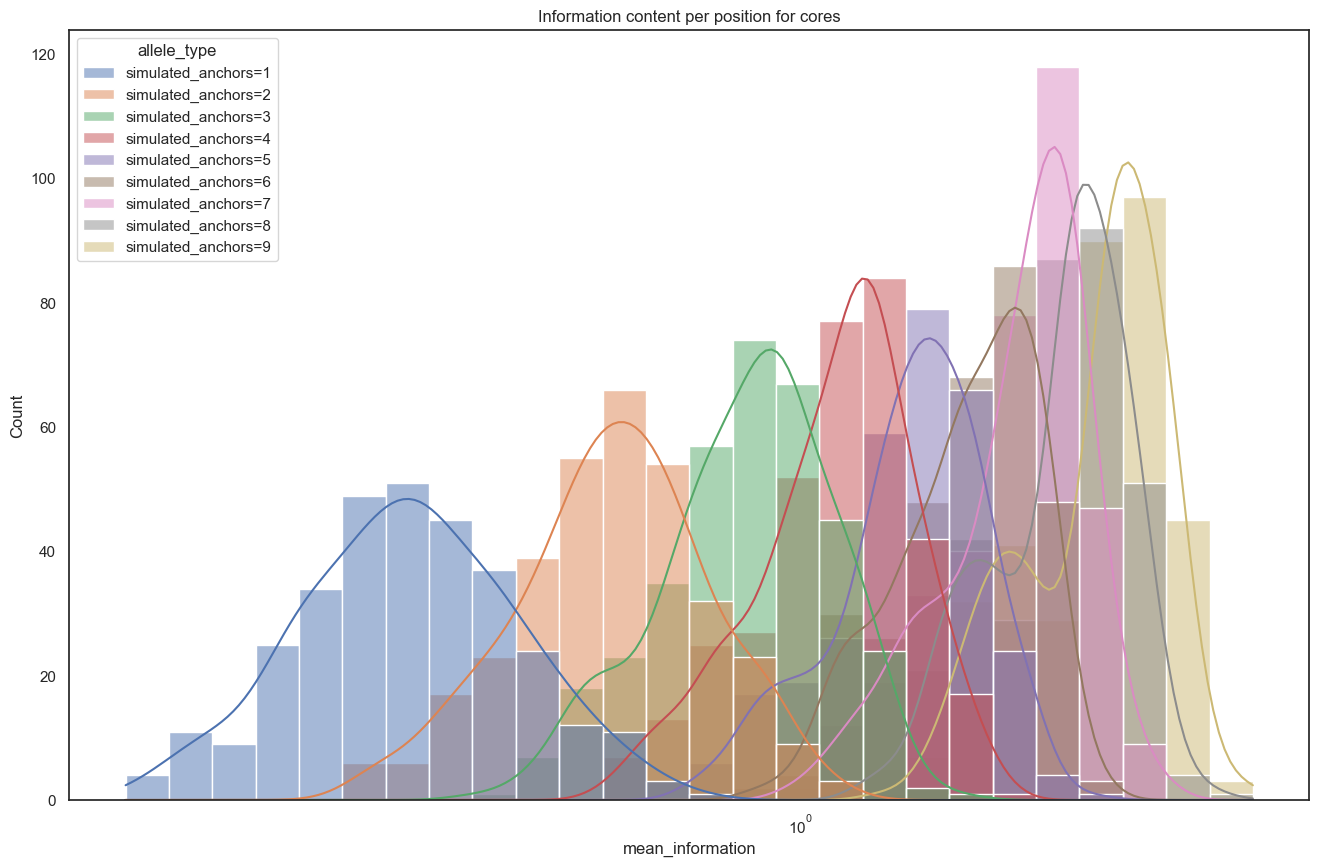

In [78]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 10))
sns.histplot(total_df[total_df.allele_type.str.startswith('simulated')],kde=True, x='mean_information', hue='allele_type', log_scale=True, ax=ax)
ax.set_title('Information content per position for cores')

### Add real data

Text(0.5, 1.0, 'Information content per position for cores')

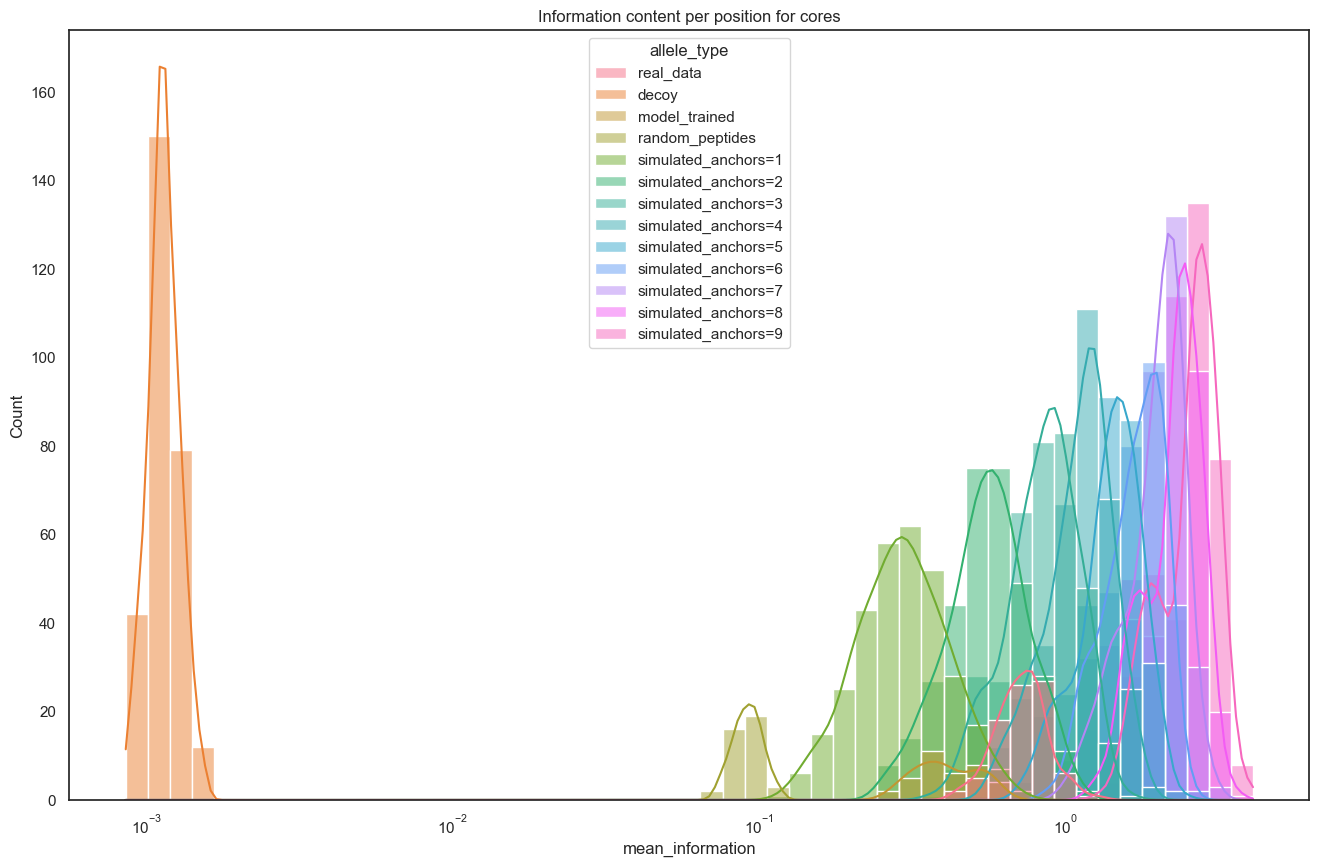

In [79]:
# total data
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 10))
sns.histplot(total_df,kde=True, x='mean_information', hue='allele_type', log_scale=True, ax=ax)
ax.set_title('Information content per position for cores')

Text(0.5, 1.0, 'Information content per position for cores')

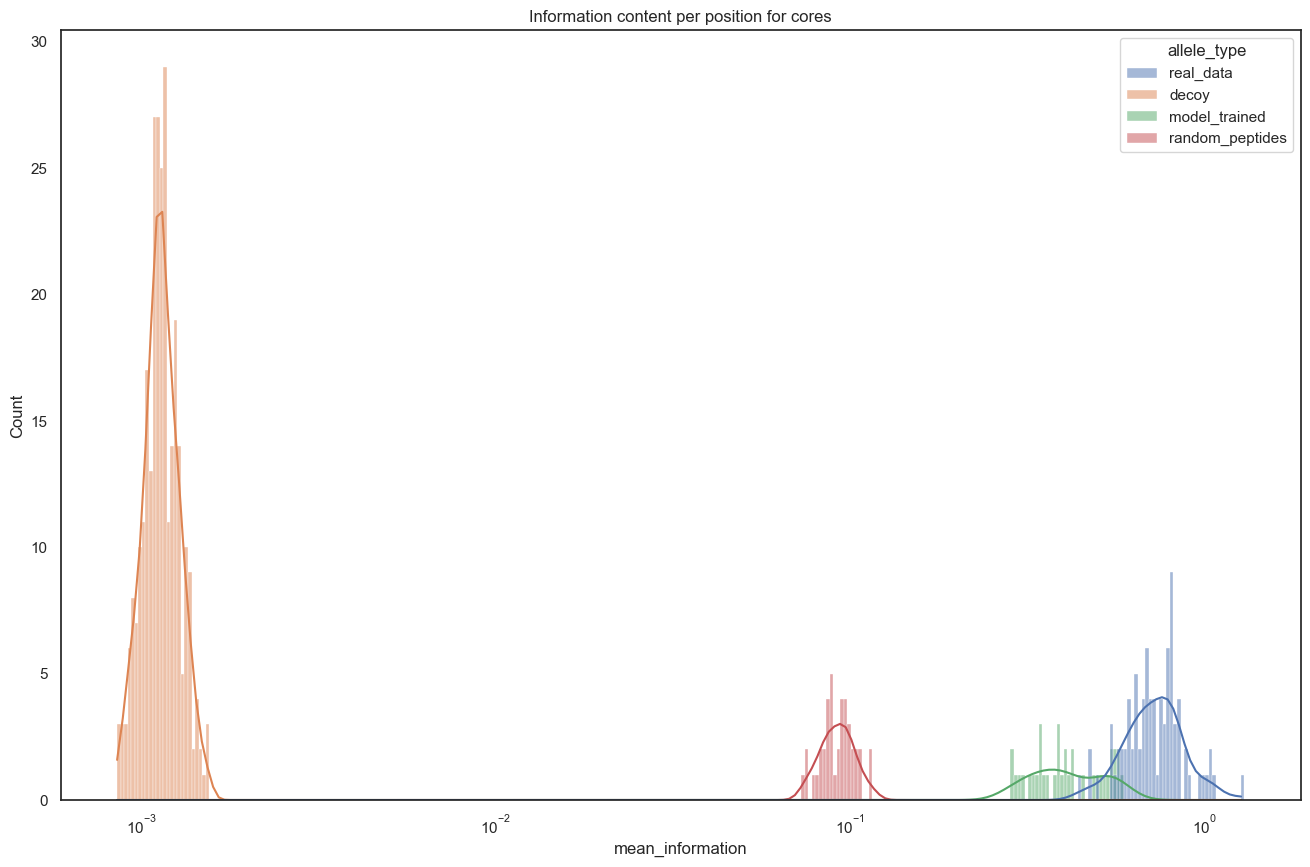

In [80]:
# total data
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 10))
sns.histplot(total_df[~(total_df.allele_type.str.startswith('simulated') )],kde=True, x='mean_information', hue='allele_type', log_scale=True, ax=ax, binwidth=1e-2)
ax.set_title('Information content per position for cores')